<a href="https://colab.research.google.com/github/ViniciusL-25/Machine_Learning/blob/main/marco2_projeto_ml_student_performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Acadêmico IESB — Aprendizagem de Máquina
## Marco 2 — Agrupamento, modelos supervisionados e avaliação comparativa

**Grupo:** Vinicius Leoncio, Caio Marques e Patrick Gonçalves
**Professor:** Rodrigo Gonçalves
**Base:** Student Performance (UCI) — Matemática + Português empilhadas (1.044 registros)

### Como usar este notebook
Execute as células **em ordem** (Ambiente de execução → Executar tudo). Leva de 5 a 10 minutos, quase todo no bloco de validação cruzada aninhada.
Células marcadas com **✏️** dependem dos números que aparecerem na sua execução: leia a saída logo acima e complete a conclusão com as palavras do grupo.

### Mapa: requisito do edital → seção

| Requisito do Marco 2 | Seção |
|---|---|
| k-means com k justificado por duas evidências e interpretação no domínio | 2 |
| Árvore de decisão (efeito da profundidade, ≥ 3 regras em linguagem do domínio) | 3 |
| Regressão linear com análise de resíduos | 4 |
| ≥ 3 modelos supervisionados de famílias distintas, mesmo protocolo, contra o baseline | 5 (árvore, KNN, Naive Bayes, rede neural) |
| Validação cruzada k-fold estratificada com média e dispersão | 5 |
| Quadro comparativo final e recomendação | 6 |
| Limitações e riscos | 8 |
| Bônus: importância de atributos e desbalanceamento antes/depois | 7 |

### Decisões que refinam o Marco 1 (citar na apresentação)
1. **Classe positiva = aluno em risco (reprovado).** O objetivo prático é encontrar quem precisa de apoio. Por isso precisão/recall/F1 agora são da classe "reprovado" (`RISCO = 1`), e os números do baseline diferem dos do Marco 1, onde a classe positiva era "aprovado".
2. **Corrigimos a limitação assumida no Marco 1:** o mesmo aluno pode aparecer em Matemática e em Português. A separação teste/desenvolvimento agora é **agrupada por aluno** (`StratifiedGroupKFold`), então nenhum aluno cai nos dois lados.
3. **Padronização dentro de `Pipeline`:** a média e o desvio são calculados só com os dados de treino de cada fold.
4. **Hiperparâmetros escolhidos em validação cruzada aninhada** (busca interna dentro de cada fold externo), para a nota não ficar otimista.
5. **G1, G2 e G3 fora das variáveis preditoras** (vazamento), como no Marco 1.

### Métricas por técnica (conferir com o quadro do Plano de Ensino)

| Técnica | Métricas usadas | Principal limitação |
|---|---|---|
| k-means | inércia (cotovelo), silhueta, Davies-Bouldin, estabilidade (ARI) | assume grupos compactos/esféricos; sensível à escala e a variáveis binárias; k é escolha heurística |
| Classificação | acurácia, acurácia balanceada, precisão/recall/F1 da classe "reprovado", ROC-AUC | acurácia engana com classes desiguais; F1 depende do limiar; AUC não define o limiar operacional |
| Regressão linear | RMSE, MAE, R², análise de resíduos | assume linearidade, variância constante e resíduos ~normais |

## 0. Ambiente, bibliotecas e carregamento dos dados

In [3]:
import os, io, zipfile, urllib.request, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold, GridSearchCV,
                                     cross_validate, cross_val_predict, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, roc_auc_score, roc_curve, log_loss, make_scorer,
                             confusion_matrix, silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

Matplotlib is building the font cache; this may take a moment.


In [4]:
# [CARREGAMENTO] Tenta o link novo do UCI, depois o antigo; se ambos falharem, pede upload.
URLS = [
    "https://archive.ics.uci.edu/static/public/320/student+performance.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip",
]

def ler_csvs_do_zip(conteudo_zip):
    # Procura student-mat.csv e student-por.csv, inclusive em zips aninhados.
    achados = {}
    with zipfile.ZipFile(io.BytesIO(conteudo_zip)) as z:
        for nome in z.namelist():
            base = nome.split("/")[-1]
            if base in ("student-mat.csv", "student-por.csv"):
                achados[base] = pd.read_csv(z.open(nome), sep=";")
            elif base.endswith(".zip"):
                achados.update(ler_csvs_do_zip(z.read(nome)))
    return achados

achados = {}
for url in URLS:
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        achados = ler_csvs_do_zip(urllib.request.urlopen(req, timeout=60).read())
        if len(achados) == 2:
            print("Dados baixados de:", url)
            break
    except Exception as e:
        print("Falhou:", url, "->", type(e).__name__, e)

if len(achados) < 2:
    print("Download automático falhou. Envie o student.zip (ou os dois CSVs) pelo botão abaixo.")
    from google.colab import files
    for nome, conteudo in files.upload().items():
        if nome.endswith(".zip"):
            achados.update(ler_csvs_do_zip(conteudo))
        elif nome.endswith(".csv"):
            achados[[k for k in ("student-mat.csv", "student-por.csv") if k.split(".")[0] in nome][0]] = \
                pd.read_csv(io.BytesIO(conteudo), sep=";")

df_mat = achados["student-mat.csv"].assign(disciplina="Matematica")
df_por = achados["student-por.csv"].assign(disciplina="Portugues")
df_raw = pd.concat([df_mat, df_por], ignore_index=True)
print("Matemática:", df_mat.shape, "| Português:", df_por.shape, "| Combinada:", df_raw.shape)

Dados baixados de: https://archive.ics.uci.edu/static/public/320/student+performance.zip
Matemática: (395, 34) | Português: (649, 34) | Combinada: (1044, 34)


## 1. Preparação dos dados e protocolo experimental

Reaproveita o pré-processamento do Marco 1, com os ajustes descritos no início do notebook.

**Separação:** 80% desenvolvimento (treino + validação por validação cruzada) e 20% teste, **estratificada pela classe e agrupada por aluno**. O conjunto de teste só é usado no final (Seção 6) para confirmar o resultado, nunca para escolher modelo ou hiperparâmetro.

In [5]:
ROTULOS = {
    # numéricas/ordinais (substantivos)
    "age": "idade", "Medu": "escolaridade da mãe (0–4)", "Fedu": "escolaridade do pai (0–4)",
    "traveltime": "tempo de deslocamento até a escola (1–4)", "studytime": "tempo de estudo semanal (1–4)",
    "failures": "nº de reprovações anteriores", "famrel": "qualidade da relação familiar (1–5)",
    "freetime": "tempo livre (1–5)", "goout": "saídas com amigos (1–5)",
    "Dalc": "consumo de álcool em dias úteis (1–5)", "Walc": "consumo de álcool no fim de semana (1–5)",
    "health": "estado de saúde (1–5)", "absences": "nº de faltas",
    # binárias (frase afirmativa = valor 1)
    "school": "estuda na escola MS", "sex": "é do sexo masculino", "address": "mora em área urbana",
    "famsize": "família com mais de 3 pessoas", "Pstatus": "pais vivem juntos",
    "schoolsup": "recebe apoio extra da escola", "famsup": "recebe apoio educacional da família",
    "paid": "faz aulas particulares pagas", "activities": "faz atividades extracurriculares",
    "nursery": "frequentou creche", "higher": "quer cursar ensino superior",
    "internet": "tem internet em casa", "romantic": "está em relacionamento",
    "Mjob_health": "mãe trabalha na saúde", "Mjob_other": "mãe tem outra profissão",
    "Mjob_services": "mãe trabalha em serviços", "Mjob_teacher": "mãe é professora",
    "Fjob_health": "pai trabalha na saúde", "Fjob_other": "pai tem outra profissão",
    "Fjob_services": "pai trabalha em serviços", "Fjob_teacher": "pai é professor",
    "reason_home": "escolheu a escola pela proximidade", "reason_other": "escolheu a escola por outro motivo",
    "reason_reputation": "escolheu a escola pela reputação",
    "guardian_mother": "responsável legal é a mãe", "guardian_other": "responsável legal é outra pessoa",
    "disciplina_Portugues": "disciplina é Português",
}

df = df_raw.copy()

# Alvo: classe positiva = aluno EM RISCO (reprovado, G3 < 10)
df["RISCO"] = (df["G3"] < 10).astype(int)

antes = len(df)
df = df.drop_duplicates()
print(f"Duplicatas exatas removidas: {antes - len(df)} | registros: {len(df)}")

# Identificador aproximado do aluno (mesmos atributos usados no script oficial de merge do UCI)
cols_id = ["school", "sex", "age", "address", "famsize", "Pstatus", "Medu", "Fedu",
           "Mjob", "Fjob", "reason", "nursery", "internet"]
df["ID_ALUNO"] = pd.factorize(df[cols_id].astype(str).agg("|".join, axis=1))[0]
print("Alunos distintos (aprox.):", df["ID_ALUNO"].nunique(), "para", len(df), "linhas")

# Metadados originais (antes da codificação) para a análise de vieses da Seção 7
meta = df[["sex", "school", "address", "disciplina"]].copy()

# Codificação (igual ao Marco 1)
for c in ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]:
    df[c] = df[c].map({"yes": 1, "no": 0})
df["school"] = df["school"].map({"GP": 0, "MS": 1})
df["sex"] = df["sex"].map({"F": 0, "M": 1})
df["address"] = df["address"].map({"R": 0, "U": 1})
df["famsize"] = df["famsize"].map({"LE3": 0, "GT3": 1})
df["Pstatus"] = df["Pstatus"].map({"A": 0, "T": 1})
df = pd.get_dummies(df, columns=["Mjob", "Fjob", "reason", "guardian", "disciplina"], drop_first=True, dtype=int)

y = df["RISCO"]
groups = df["ID_ALUNO"]
nota = df["G3"]
X = df.drop(columns=["G1", "G2", "G3", "RISCO", "ID_ALUNO"])   # G1/G2/G3 fora: vazamento

print("Atributos preditores:", X.shape[1], "| valores ausentes:", int(X.isnull().sum().sum()))
if X.isnull().sum().sum() > 0:
    X = X.fillna(X.median())
print(f"Proporção de alunos em risco (reprovados): {y.mean():.1%}")

Duplicatas exatas removidas: 0 | registros: 1044
Alunos distintos (aprox.): 662 para 1044 linhas
Atributos preditores: 40 | valores ausentes: 0
Proporção de alunos em risco (reprovados): 22.0%


In [6]:
# Separação 80% desenvolvimento / 20% teste: estratificada E agrupada por aluno
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_dev, idx_test = next(sgkf.split(X, y, groups))

X_dev, X_test = X.iloc[idx_dev], X.iloc[idx_test]
y_dev, y_test = y.iloc[idx_dev], y.iloc[idx_test]
g_dev = groups.iloc[idx_dev]
nota_dev, nota_test = nota.iloc[idx_dev], nota.iloc[idx_test]
meta_test = meta.iloc[idx_test]

print(f"Desenvolvimento: {X_dev.shape} | risco = {y_dev.mean():.1%}")
print(f"Teste:           {X_test.shape} | risco = {y_test.mean():.1%}")
print("Alunos presentes em desenvolvimento E teste:", len(set(groups.iloc[idx_dev]) & set(groups.iloc[idx_test])))

# Os MESMOS folds serão usados por todos os modelos (comparação pareada e justa)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_dev, y_dev))
folds_grupo = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_dev, y_dev, g_dev))
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # busca de hiperparâmetros

Desenvolvimento: (835, 40) | risco = 22.0%
Teste:           (209, 40) | risco = 22.0%
Alunos presentes em desenvolvimento E teste: 0


In [7]:
# Métricas de classificação (classe positiva = 1 = reprovado) e funções auxiliares
scorers = {
    "accuracy":  "accuracy",
    "bal_acc":   "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    make_scorer(recall_score, zero_division=0),
    "f1":        make_scorer(f1_score, zero_division=0),
    "roc_auc":   "roc_auc",
}
ROT_METRICAS = {"accuracy": "Acurácia", "bal_acc": "Acurácia balanceada", "precision": "Precisão (risco)",
                "recall": "Recall (risco)", "f1": "F1 (risco)", "roc_auc": "ROC-AUC"}

def avaliar(modelo, cv_folds=None):
    cv_folds = folds if cv_folds is None else cv_folds
    return cross_validate(modelo, X_dev, y_dev, cv=cv_folds, scoring=scorers, n_jobs=-1)

def tabela_cv(resultados):
    linhas = []
    for nome, res in resultados.items():
        linha = {"Modelo": nome}
        for m, rot in ROT_METRICAS.items():
            v = res[f"test_{m}"]
            linha[rot] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("Modelo")

def metricas_teste(y_true, proba, limiar=0.5):
    pred = (np.asarray(proba) >= limiar).astype(int)
    return {"Acurácia": accuracy_score(y_true, pred),
            "Acurácia balanceada": balanced_accuracy_score(y_true, pred),
            "Precisão (risco)": precision_score(y_true, pred, zero_division=0),
            "Recall (risco)": recall_score(y_true, pred, zero_division=0),
            "F1 (risco)": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba)}

# Baseline sob o MESMO protocolo: sempre prevê a classe majoritária (aprovado)
res_baseline = avaliar(DummyClassifier(strategy="most_frequent"))
print("=== Baseline (validação cruzada 5-fold estratificada, média ± desvio) ===")
display(tabela_cv({"Baseline (classe majoritária)": res_baseline}))

=== Baseline (validação cruzada 5-fold estratificada, média ± desvio) ===


,Acurácia,Acurácia balanceada,Precisão (risco),Recall (risco),F1 (risco),ROC-AUC
Modelo,,,,,,
Baseline (classe majoritária),0.780 ± 0.003,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000


**Leitura do baseline:** como a grande maioria dos alunos é aprovada (a proporção exata foi impressa na Seção 1), prever "aprovado" para todos já rende acurácia alta, mas **recall, precisão e F1 da classe "reprovado" são zero** e a ROC-AUC é 0,5 (nenhum poder de ranqueamento). Qualquer modelo útil precisa superar o baseline nas métricas da classe de risco, não só na acurácia.

## 2. Aprendizagem não supervisionada — k-means

**Objetivo:** descobrir perfis de alunos *sem usar o rótulo*. O rótulo (reprovação) só entra depois, para validar externamente se os grupos fazem sentido.

**Atributos usados no agrupamento:** variáveis numéricas/ordinais e binárias (sim/não, escola, sexo...). Os *dummies* de variáveis nominais com várias categorias (profissão dos pais, motivo da escola, responsável, disciplina) ficam de fora: com distância euclidiana, eles inflariam artificialmente a dimensionalidade. A disciplina é usada só para descrever os grupos.

O k-means roda **apenas nos dados de desenvolvimento** (o teste não é tocado) e com atributos padronizados, porque a distância euclidiana é sensível à escala.

26 atributos no agrupamento


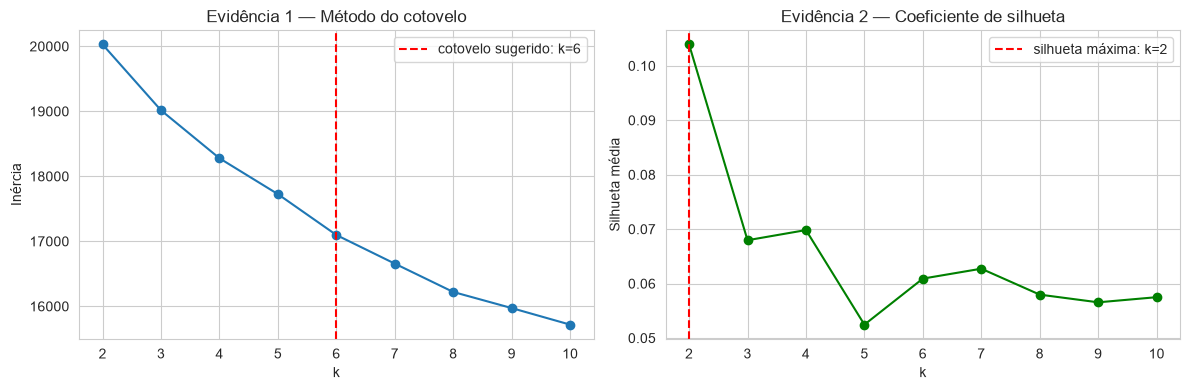

,inércia,silhueta,Davies-Bouldin (menor é melhor)
k,,,
2,20028.5,0.104,3.330
3,19015.6,0.068,3.274
4,18277.7,0.070,3.004
5,17725.8,0.052,3.062
6,17097.3,0.061,2.868
7,16656.5,0.063,2.759
8,16220.4,0.058,2.654
9,15972.8,0.057,2.664
10,15717.8,0.058,2.579


Cotovelo sugere k=6; silhueta sugere k=2 (silhueta máxima = 0.104).


In [8]:
num_ord = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures", "famrel",
           "freetime", "goout", "Dalc", "Walc", "health", "absences"]
prefixos_nominais = ("Mjob_", "Fjob_", "reason_", "guardian_", "disciplina_")
bin_cols = [c for c in X_dev.columns if c not in num_ord and not c.startswith(prefixos_nominais)]
cluster_feats = num_ord + bin_cols
print(len(cluster_feats), "atributos no agrupamento")

esc_km = StandardScaler().fit(X_dev[cluster_feats])
Z = esc_km.transform(X_dev[cluster_feats])

ks = list(range(2, 11))
inercia, silh, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inercia.append(km.inertia_)
    silh.append(silhouette_score(Z, km.labels_))
    dbi.append(davies_bouldin_score(Z, km.labels_))

def k_cotovelo(ks, inercia):
    # Ponto mais distante da reta entre o primeiro e o último ponto (eixos normalizados)
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
    v = np.array(inercia); v = (v - v.min()) / (v.max() - v.min())
    corda = v[0] + (v[-1] - v[0]) * x
    return ks[int(np.argmax(corda - v))]

k_cot = k_cotovelo(ks, inercia)
k_sil = ks[int(np.argmax(silh))]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercia, "o-"); ax[0].axvline(k_cot, color="red", ls="--", label=f"cotovelo sugerido: k={k_cot}")
ax[0].set_title("Evidência 1 — Método do cotovelo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inércia"); ax[0].legend()
ax[1].plot(ks, silh, "o-", color="green"); ax[1].axvline(k_sil, color="red", ls="--", label=f"silhueta máxima: k={k_sil}")
ax[1].set_title("Evidência 2 — Coeficiente de silhueta"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhueta média"); ax[1].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({"k": ks, "inércia": np.round(inercia, 1), "silhueta": np.round(silh, 3),
                      "Davies-Bouldin (menor é melhor)": np.round(dbi, 3)}).set_index("k"))
print(f"Cotovelo sugere k={k_cot}; silhueta sugere k={k_sil} (silhueta máxima = {max(silh):.3f}).")

**Como ler (Gráfico K1):** são duas evidências independentes. O **cotovelo** mostra onde um grupo a mais deixa de reduzir bastante a inércia (compactação interna). A **silhueta** compara, para cada aluno, a distância ao próprio grupo com a distância ao grupo vizinho (de −1 a 1; abaixo de ~0,25 a estrutura é considerada fraca). O Davies-Bouldin é um terceiro termômetro (menor é melhor).

**✏️ Conclusão do grupo:** diga qual k vocês escolheram e por quê. Se os critérios divergirem, justifique (ex.: priorizar a silhueta e conferir se os grupos fazem sentido no domínio). Se a silhueta máxima for baixa, afirme isso com todas as letras: **estrutura de grupos fraca é um resultado legítimo**, não um erro.

k escolhido: 2
Estabilidade (ARI médio entre execuções): 0.929 ± 0.056  (1 = idêntico)

=== Perfil e validação externa (rótulo NÃO usado no agrupamento) ===


,n,% do total,taxa de risco (reprovação),nota final G3 média,% Português
grupo,,,,,
0,536,64.2,0.155,12.21,56.7
1,299,35.8,0.338,9.82,72.6



=== O que mais distingue cada grupo (desvios-padrão em relação à média geral) ===
Grupo 0 (n=536, risco=15.5%): escolaridade da mãe (0–4) acima da média (z=+0.37); estuda na escola MS abaixo da média (z=-0.36); tempo de deslocamento até a escola (1–4) abaixo da média (z=-0.35); escolaridade do pai (0–4) acima da média (z=+0.34); mora em área urbana acima da média (z=+0.31)
Grupo 1 (n=299, risco=33.8%): escolaridade da mãe (0–4) abaixo da média (z=-0.67); estuda na escola MS acima da média (z=+0.65); tempo de deslocamento até a escola (1–4) acima da média (z=+0.62); escolaridade do pai (0–4) abaixo da média (z=-0.61); mora em área urbana abaixo da média (z=-0.55)


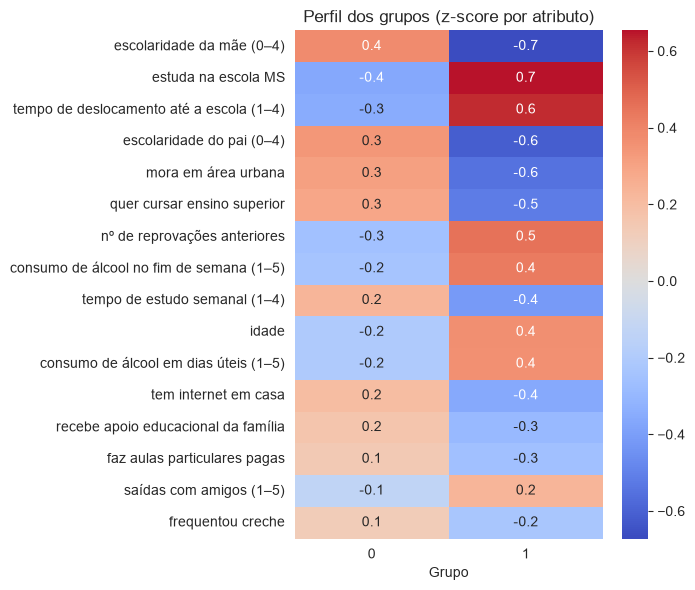

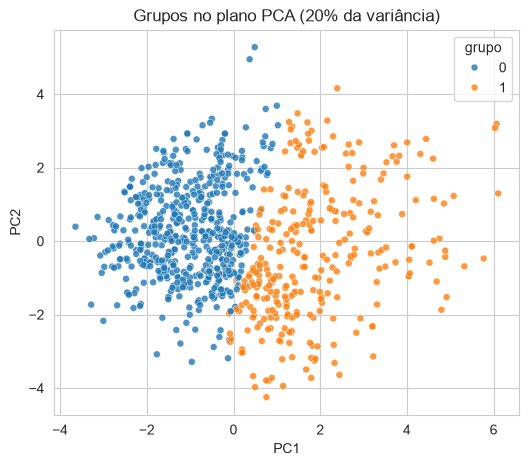

In [9]:
# k escolhido: por padrão, o da silhueta. Ajuste manualmente se o grupo justificar outro valor.
K_ESCOLHIDO = k_sil
print("k escolhido:", K_ESCOLHIDO)

km_final = KMeans(n_clusters=K_ESCOLHIDO, n_init=10, random_state=SEED).fit(Z)
rot_km = km_final.labels_

# Estabilidade: concordância (ARI) com 10 reinicializações independentes
aris = [adjusted_rand_score(rot_km, KMeans(n_clusters=K_ESCOLHIDO, n_init=1, random_state=100 + s).fit_predict(Z))
        for s in range(10)]
print(f"Estabilidade (ARI médio entre execuções): {np.mean(aris):.3f} ± {np.std(aris, ddof=1):.3f}  (1 = idêntico)")

# Perfil dos grupos
dev_cl = X_dev[cluster_feats].copy()
dev_cl["cluster"] = rot_km
resumo = pd.DataFrame({
    "n": pd.Series(rot_km).value_counts().sort_index(),
    "% do total": (pd.Series(rot_km).value_counts(normalize=True).sort_index() * 100).round(1),
    "taxa de risco (reprovação)": y_dev.groupby(rot_km).mean().round(3),
    "nota final G3 média": nota_dev.groupby(rot_km).mean().round(2),
    "% Português": (X_dev["disciplina_Portugues"].groupby(rot_km).mean() * 100).round(1),
})
resumo.index.name = "grupo"
print("\n=== Perfil e validação externa (rótulo NÃO usado no agrupamento) ===")
display(resumo)

medias = dev_cl.groupby("cluster")[cluster_feats].mean()
zsc = (medias - dev_cl[cluster_feats].mean()) / dev_cl[cluster_feats].std()

print("\n=== O que mais distingue cada grupo (desvios-padrão em relação à média geral) ===")
for c in zsc.index:
    top = zsc.loc[c].reindex(zsc.loc[c].abs().sort_values(ascending=False).index).head(5)
    traco = "; ".join(f"{ROTULOS.get(f, f)} {'acima' if v > 0 else 'abaixo'} da média (z={v:+.2f})" for f, v in top.items())
    print(f"Grupo {c} (n={int(resumo.loc[c, 'n'])}, risco={resumo.loc[c, 'taxa de risco (reprovação)']:.1%}): {traco}")

cols_plot = zsc.abs().max().sort_values(ascending=False).head(16).index
plt.figure(figsize=(7, 6))
sns.heatmap(zsc[cols_plot].T.rename(index=lambda f: ROTULOS.get(f, f)), annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Perfil dos grupos (z-score por atributo)"); plt.xlabel("Grupo"); plt.tight_layout(); plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
plt.figure(figsize=(6, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=rot_km, palette="tab10", s=25, alpha=0.8)
plt.title(f"Grupos no plano PCA ({pca.explained_variance_ratio_.sum():.0%} da variância)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(title="grupo"); plt.show()

**✏️ Interpretação dos grupos no domínio (Gráficos K2–K3):** com a tabela de perfil e o mapa de calor acima, dê um **nome e uma descrição** a cada grupo em linguagem de escola (ex.: "alunos com histórico de reprovação e mais faltas", "alunos com forte apoio familiar e planos de ensino superior"). Compare as taxas de risco entre os grupos: se forem bem diferentes, os grupos capturam algo relevante para o problema, embora o agrupamento nunca tenha visto o rótulo.

**Limitações a citar:** (i) o k-means supõe grupos compactos e de tamanho parecido; (ii) misturar variáveis ordinais e binárias com distância euclidiana é uma aproximação; (iii) o gráfico PCA em 2D mostra só uma fração da variância, e grupos que parecem sobrepostos ali podem estar separados nas demais dimensões; (iv) a estabilidade (ARI) baixa indicaria que os grupos mudam conforme a inicialização.

## 3. Árvore de decisão — efeito da profundidade e regras

A árvore é o modelo mais interpretável do projeto. Primeiro estudamos como a **profundidade máxima** afeta o erro de treino e o de validação (validação cruzada 5-fold estratificada); depois extraímos regras.

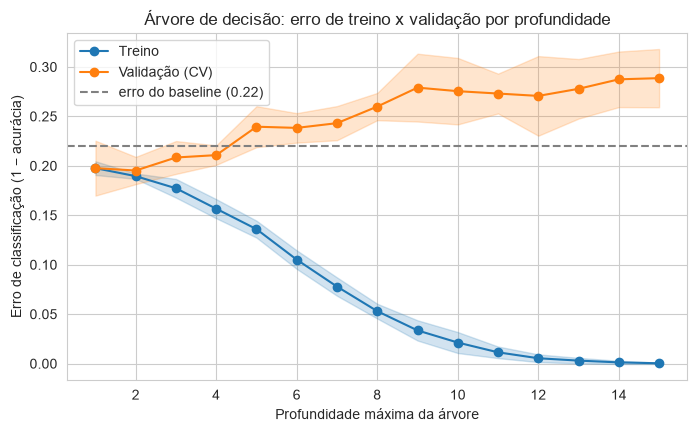

Menor erro de validação: profundidade 2 (erro = 0.195).
Profundidade escolhida pela regra de 1 erro-padrão (árvore mais simples equivalente): 1
Erro de treino na profundidade máxima testada: 0.000 | erro de validação: 0.289


In [16]:
profundidades = list(range(1, 16))
tr, va = validation_curve(DecisionTreeClassifier(random_state=SEED), X_dev, y_dev,
                          param_name="max_depth", param_range=profundidades, cv=folds, scoring="accuracy")
err_tr, err_va = 1 - tr, 1 - va
erro_baseline = 1 - max(y_dev.mean(), 1 - y_dev.mean())

plt.figure(figsize=(8, 4.5))
for err, rot, cor in [(err_tr, "Treino", "tab:blue"), (err_va, "Validação (CV)", "tab:orange")]:
    m, s = err.mean(axis=1), err.std(axis=1, ddof=1)
    plt.plot(profundidades, m, "o-", label=rot, color=cor)
    plt.fill_between(profundidades, m - s, m + s, alpha=0.2, color=cor)
plt.axhline(erro_baseline, color="gray", ls="--", label=f"erro do baseline ({erro_baseline:.2f})")
plt.xlabel("Profundidade máxima da árvore"); plt.ylabel("Erro de classificação (1 − acurácia)")
plt.title("Árvore de decisão: erro de treino x validação por profundidade"); plt.legend(); plt.show()

m_va, s_va = err_va.mean(axis=1), err_va.std(axis=1, ddof=1)
i_min = int(np.argmin(m_va))
limite = m_va[i_min] + s_va[i_min] / np.sqrt(len(folds))             # regra de 1 erro-padrão
prof_escolhida = int(next(p for p, m in zip(profundidades, m_va) if m <= limite))
print(f"Menor erro de validação: profundidade {profundidades[i_min]} (erro = {m_va[i_min]:.3f}).")
print(f"Profundidade escolhida pela regra de 1 erro-padrão (árvore mais simples equivalente): {prof_escolhida}")
print(f"Erro de treino na profundidade máxima testada: {err_tr.mean(axis=1)[-1]:.3f} | erro de validação: {m_va[-1]:.3f}")

**Como ler (Gráfico A1):** com profundidade pequena, treino e validação têm erro alto e parecido (**subajuste**: modelo simples demais). Conforme a árvore aprofunda, o erro de **treino** despenca (ela "decora" os dados), enquanto o de **validação** para de melhorar e pode até subir (**sobreajuste**). A distância crescente entre as duas curvas é o diagnóstico.

**✏️ Conclusão do grupo:** em que profundidade o erro de validação para de cair? Em que ponto o erro de treino se separa do de validação? Compare a menor taxa de erro obtida com a linha do baseline: o ganho em acurácia é grande ou pequeno? (Lembre: acurácia não é a métrica mais informativa aqui; a Seção 5 mostra o ganho nas métricas da classe de risco.)

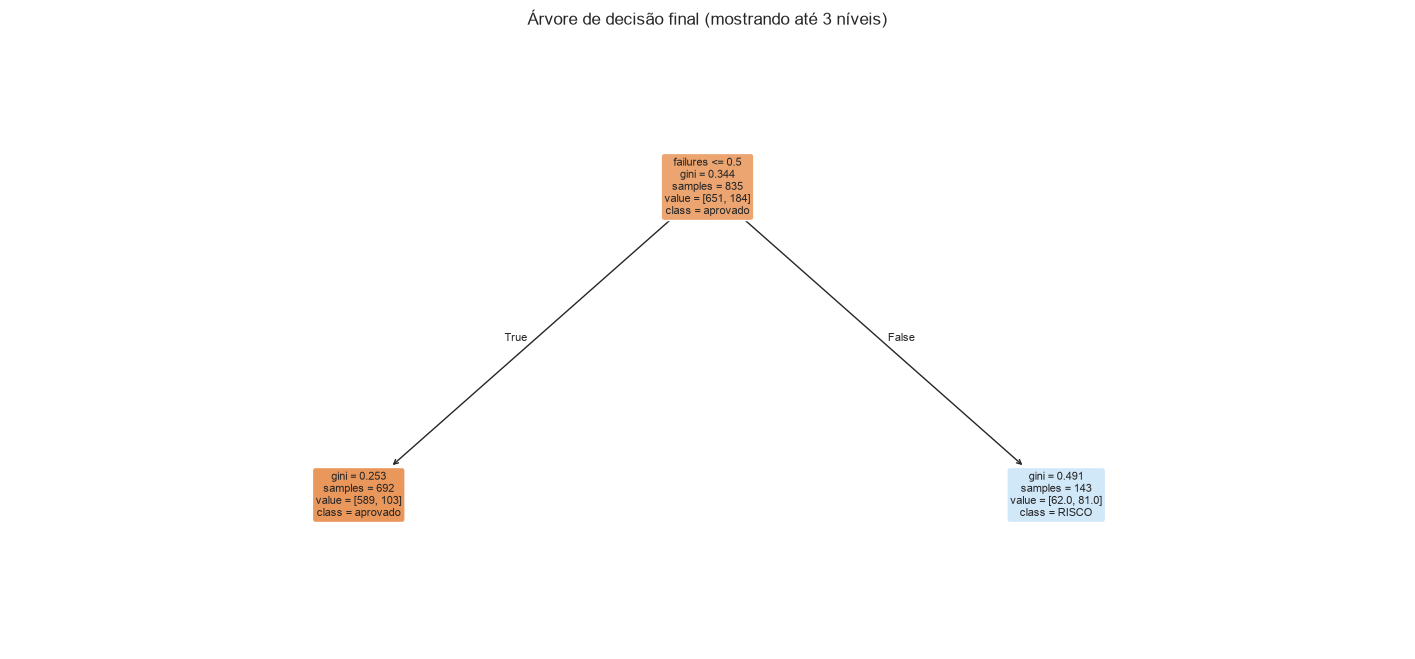

Taxa geral de risco no desenvolvimento: 22.0%

=== Regras de MAIOR risco (com pelo menos 15 alunos) ===
REGRA 1: SE nº de reprovações anteriores ≥ 1
   ENTÃO risco de reprovação = 57% (n = 143)

REGRA 2: SE nº de reprovações anteriores = 0
   ENTÃO risco de reprovação = 15% (n = 692)

=== Regras de MENOR risco ===
REGRA B1: SE nº de reprovações anteriores = 0
   ENTÃO risco de reprovação = 15% (n = 692)

REGRA B2: SE nº de reprovações anteriores ≥ 1
   ENTÃO risco de reprovação = 57% (n = 143)



In [17]:
arvore = DecisionTreeClassifier(max_depth=prof_escolhida, min_samples_leaf=10, random_state=SEED).fit(X_dev, y_dev)

plt.figure(figsize=(18, 8))
plot_tree(arvore, feature_names=list(X_dev.columns), class_names=["aprovado", "RISCO"], filled=True,
          rounded=True, max_depth=3, fontsize=8)
plt.title("Árvore de decisão final (mostrando até 3 níveis)"); plt.show()

def texto_intervalo(f, lo, hi):
    # Converte limites (lo < valor <= hi) em frase do domínio
    desc = ROTULOS.get(f, f)
    valores = X_dev[f].values
    if set(np.unique(valores)) <= {0, 1}:
        return desc if lo is not None else f"NÃO ({desc})"
    if np.all(np.mod(valores, 1) == 0):                       # atributo inteiro: 2,5 vira "≥ 3" / "≤ 2"
        a = None if lo is None else int(np.floor(lo)) + 1
        b = None if hi is None else int(np.floor(hi))
        if a is None and b == int(valores.min()):
            return f"{desc} = {b}"
        if b is None and a == int(valores.max()):
            return f"{desc} = {a}"
        if a is not None and b is not None:
            return f"{desc} = {a}" if a == b else f"{desc} entre {a} e {b}"
        return f"{desc} ≥ {a}" if a is not None else f"{desc} ≤ {b}"
    if lo is not None and hi is not None:
        return f"{lo:.1f} < {desc} ≤ {hi:.1f}"
    return f"{desc} > {lo:.1f}" if lo is not None else f"{desc} ≤ {hi:.1f}"

def extrair_regras(clf, X, y):
    t = clf.tree_
    folha_de = clf.apply(X)
    regras = []
    def percorre(no, lim):
        if t.children_left[no] == t.children_right[no]:
            m = folha_de == no
            n = int(m.sum())
            regras.append({"condicoes": [texto_intervalo(f, lo, hi) for f, (lo, hi) in lim.items()] or ["(todos os alunos)"],
                           "n": n, "pct_risco": float(y.values[m].mean()) if n else np.nan})
            return
        f, thr = X.columns[t.feature[no]], t.threshold[no]
        esq = {k: list(v) for k, v in lim.items()}; esq.setdefault(f, [None, None])
        esq[f][1] = thr if esq[f][1] is None else min(esq[f][1], thr)
        dire = {k: list(v) for k, v in lim.items()}; dire.setdefault(f, [None, None])
        dire[f][0] = thr if dire[f][0] is None else max(dire[f][0], thr)
        percorre(t.children_left[no], esq)
        percorre(t.children_right[no], dire)
    percorre(0, {})
    return pd.DataFrame(regras)

regras = extrair_regras(arvore, X_dev, y_dev)
base = y_dev.mean()
validas = regras[regras["n"] >= 15]
print(f"Taxa geral de risco no desenvolvimento: {base:.1%}\n")
print("=== Regras de MAIOR risco (com pelo menos 15 alunos) ===")
for i, r in enumerate(validas.sort_values("pct_risco", ascending=False).head(3).itertuples(), 1):
    print(f"REGRA {i}: SE " + " E ".join(r.condicoes) + f"\n   ENTÃO risco de reprovação = {r.pct_risco:.0%} (n = {r.n})\n")
print("=== Regras de MENOR risco ===")
for i, r in enumerate(validas.sort_values("pct_risco").head(2).itertuples(), 1):
    print(f"REGRA B{i}: SE " + " E ".join(r.condicoes) + f"\n   ENTÃO risco de reprovação = {r.pct_risco:.0%} (n = {r.n})\n")

**✏️ Leitura de ao menos três regras (exigência do edital):** escolha as três regras de maior risco impressas acima e reescreva cada uma como uma frase para um coordenador pedagógico (ex.: "alunos com 1 ou mais reprovações anteriores e mais de X faltas têm risco de ~Y%, contra a taxa geral impressa acima"). Comente se a regra é plausível e se há risco de ela refletir **correlação sem causa**.

**Cuidados ao falar das regras:** cada regra vem de um subconjunto pequeno de alunos (veja o `n`); as taxas têm incerteza grande, e a árvore é instável (outra amostra pode gerar outras regras). Elas servem para **entender**, não para decidir sobre um aluno.

## 4. Regressão linear — nota final (G3) com análise de resíduos

Como `G3` (0 a 20) é numérica, a regressão linear é viável. Ela complementa a classificação: em vez de "reprova ou não", estima a **nota**. Mesma regra anti-vazamento (sem G1/G2) e **mesmos folds** da classificação. O baseline é prever sempre a média.

=== Regressão (CV 5-fold, média ± desvio) ===


,RMSE,MAE,R²
Baseline (média),3.87 ± 0.17,2.84 ± 0.13,-0.003 ± 0.003
Regressão linear,3.43 ± 0.14,2.49 ± 0.14,0.209 ± 0.047


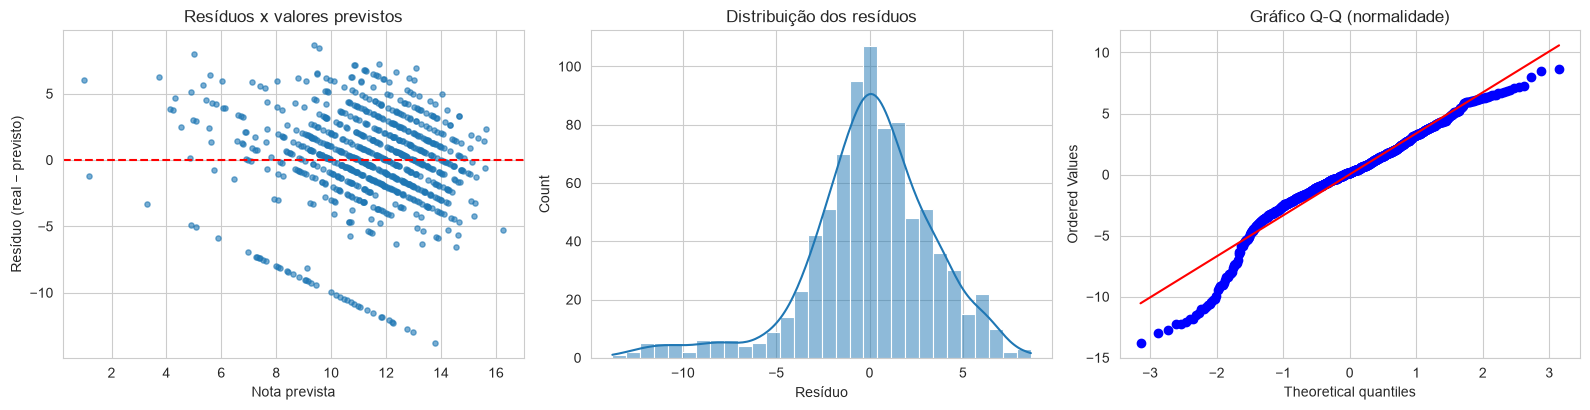

Resíduo médio: +0.020 | desvio: 3.44 | assimetria: -0.86 | curtose: +1.98
Desvio dos resíduos por faixa de nota prevista (variância constante?):
(1.0030000000000001, 10.151]    3.87
(10.151, 11.573]                3.58
(11.573, 12.87]                 3.31
(12.87, 16.246]                 2.85
Resíduos abaixo de −5 pontos: 6.6% (prováveis notas zero de abandono)

Maiores coeficientes padronizados (efeito em pontos de nota por 1 desvio-padrão do atributo):
nº de reprovações anteriores    -1.08
disciplina é Português           0.98
pai trabalha em serviços        -0.53
quer cursar ensino superior      0.50
pai tem outra profissão         -0.46
mãe trabalha em serviços         0.39
estuda na escola MS             -0.34
mãe trabalha na saúde            0.34
tempo de estudo semanal (1–4)    0.33
recebe apoio extra da escola    -0.31


In [13]:
reg = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())])
sc_reg = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

res_reg = cross_validate(reg, X_dev, nota_dev, cv=folds, scoring=sc_reg, n_jobs=-1)
res_dum = cross_validate(DummyRegressor(strategy="mean"), X_dev, nota_dev, cv=folds, scoring=sc_reg, n_jobs=-1)

def linha_reg(res):
    return {"RMSE": f"{-res['test_rmse'].mean():.2f} ± {res['test_rmse'].std(ddof=1):.2f}",
            "MAE": f"{-res['test_mae'].mean():.2f} ± {res['test_mae'].std(ddof=1):.2f}",
            "R²": f"{res['test_r2'].mean():.3f} ± {res['test_r2'].std(ddof=1):.3f}"}
print("=== Regressão (CV 5-fold, média ± desvio) ===")
display(pd.DataFrame({"Baseline (média)": linha_reg(res_dum), "Regressão linear": linha_reg(res_reg)}).T)

# Resíduos fora da amostra (cada aluno previsto por um modelo que não o viu)
pred_oof = cross_val_predict(reg, X_dev, nota_dev, cv=folds)
resid = nota_dev.values - pred_oof

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(pred_oof, resid, s=14, alpha=0.6); ax[0].axhline(0, color="red", ls="--")
ax[0].set_title("Resíduos x valores previstos"); ax[0].set_xlabel("Nota prevista"); ax[0].set_ylabel("Resíduo (real − previsto)")
sns.histplot(resid, bins=30, kde=True, ax=ax[1]); ax[1].set_title("Distribuição dos resíduos"); ax[1].set_xlabel("Resíduo")
stats.probplot(resid, dist="norm", plot=ax[2]); ax[2].set_title("Gráfico Q-Q (normalidade)")
plt.tight_layout(); plt.show()

faixas = pd.qcut(pd.Series(pred_oof), 4, duplicates="drop")
print(f"Resíduo médio: {resid.mean():+.3f} | desvio: {resid.std(ddof=1):.2f} | assimetria: {stats.skew(resid):+.2f} | curtose: {stats.kurtosis(resid):+.2f}")
print("Desvio dos resíduos por faixa de nota prevista (variância constante?):")
print(pd.Series(resid).groupby(faixas).std().round(2).to_string())
print(f"Resíduos abaixo de −5 pontos: {(resid < -5).mean():.1%} (prováveis notas zero de abandono)")

lr_final = reg.fit(X_dev, nota_dev).named_steps["lr"]
coef = pd.Series(lr_final.coef_, index=X_dev.columns)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
print("\nMaiores coeficientes padronizados (efeito em pontos de nota por 1 desvio-padrão do atributo):")
print(top_coef.rename(index=lambda f: ROTULOS.get(f, f)).round(2).to_string())

**Como ler (Gráficos R1–R3):** (R1) se o modelo linear fosse adequado, os resíduos ficariam espalhados ao acaso em torno de zero, com a mesma largura em todas as faixas; funil ou curva indicam falta de linearidade ou **heterocedasticidade**. (R2–R3) o histograma e o Q-Q mostram se os resíduos são ~normais; cauda pesada à esquerda sugere um grupo que o modelo não captura.

**✏️ Conclusão do grupo:** compare RMSE/MAE/R² com o baseline da média (o ganho é grande ou pequeno? R² baixo significa que os atributos explicam pouco da nota). Aponte qual pressuposto os resíduos violam. Dica: os alunos com **nota 0** (provável abandono) são um fenômeno diferente de "nota baixa"; o modelo linear os trata como ponto extremo e isso puxa os resíduos para a esquerda. Os coeficientes são **associações**, não causas.

## 5. Modelos supervisionados de famílias distintas (classificação de risco)

| Família | Modelo | Hiperparâmetros buscados (validação cruzada interna) |
|---|---|---|
| Regras / árvores | Árvore de decisão | profundidade máxima, tamanho mínimo da folha |
| Baseada em instâncias | k-vizinhos mais próximos (KNN) | k, ponderação por distância |
| Probabilística | Naive Bayes Gaussiano | suavização da variância |
| Neural | Rede neural multicamada (MLP) | arquitetura, regularização L2 |

**Protocolo idêntico para todos (e para o baseline):**
- mesmos 5 folds estratificados do conjunto de desenvolvimento;
- padronização dentro do `Pipeline` (só com dados de treino de cada fold), exceto na árvore, que não precisa de escala;
- **validação cruzada aninhada:** em cada fold externo, a busca de hiperparâmetros usa só o treino daquele fold (3-fold interno, critério ROC-AUC, que não depende do limiar);
- resultado = **média ± desvio** nos 5 folds. Um número isolado não é resultado.

In [14]:
modelos = {
    "Árvore de decisão": GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 40]},
        cv=cv_interno, scoring="roc_auc"),
    "KNN": GridSearchCV(
        Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier())]),
        {"knn__n_neighbors": [9, 15, 25, 35, 51, 71], "knn__weights": ["uniform", "distance"]},
        cv=cv_interno, scoring="roc_auc"),
    "Naive Bayes": GridSearchCV(
        Pipeline([("sc", StandardScaler()), ("nb", GaussianNB())]),
        {"nb__var_smoothing": [1e-6, 1e-3, 1e-2, 1e-1, 0.5, 1.0, 2.0]},
        cv=cv_interno, scoring="roc_auc"),
    "Rede neural (MLP)": GridSearchCV(
        Pipeline([("sc", StandardScaler()),
                  ("mlp", MLPClassifier(max_iter=500, random_state=SEED))]),
        {"mlp__hidden_layer_sizes": [(8,), (16,), (32, 16)], "mlp__alpha": [1e-2, 1e-1, 1.0, 10.0]},
        cv=cv_interno, scoring="roc_auc"),
}

resultados = {"Baseline (classe majoritária)": res_baseline}
for nome, m in modelos.items():
    print("Validação cruzada aninhada:", nome, "...")
    resultados[nome] = avaliar(m)

print("\n=== Validação cruzada 5-fold estratificada (média ± desvio-padrão entre folds) ===")
tab_cv = tabela_cv(resultados)
display(tab_cv)

Validação cruzada aninhada: Árvore de decisão ...
Validação cruzada aninhada: KNN ...
Validação cruzada aninhada: Naive Bayes ...
Validação cruzada aninhada: Rede neural (MLP) ...

=== Validação cruzada 5-fold estratificada (média ± desvio-padrão entre folds) ===


,Acurácia,Acurácia balanceada,Precisão (risco),Recall (risco),F1 (risco),ROC-AUC
Modelo,,,,,,
Baseline (classe majoritária),0.780 ± 0.003,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Árvore de decisão,0.802 ± 0.018,0.599 ± 0.026,0.665 ± 0.110,0.234 ± 0.057,0.340 ± 0.065,0.764 ± 0.046
KNN,0.786 ± 0.008,0.515 ± 0.018,0.500 ± 0.500,0.032 ± 0.035,0.061 ± 0.066,0.780 ± 0.022
Naive Bayes,0.787 ± 0.011,0.559 ± 0.023,0.566 ± 0.099,0.152 ± 0.056,0.235 ± 0.072,0.758 ± 0.039
Rede neural (MLP),0.795 ± 0.027,0.594 ± 0.036,0.670 ± 0.186,0.233 ± 0.096,0.325 ± 0.099,0.781 ± 0.033


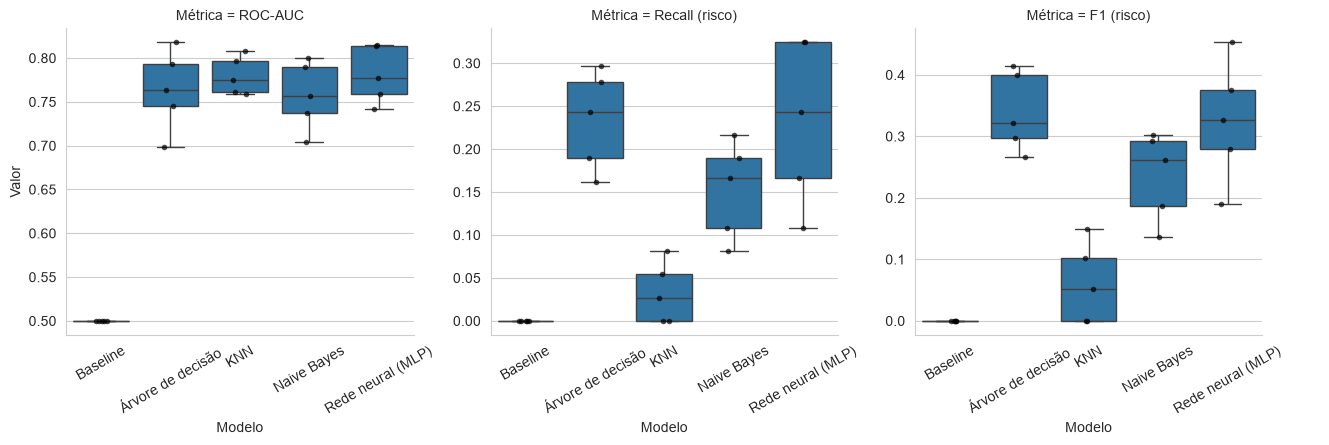

In [18]:
# Dispersão fold a fold (um número isolado não é resultado)
linhas = []
for nome, res in resultados.items():
    for m, rot in [("roc_auc", "ROC-AUC"), ("recall", "Recall (risco)"), ("f1", "F1 (risco)")]:
        for v in res[f"test_{m}"]:
            linhas.append({"Modelo": nome.replace(" (classe majoritária)", ""), "Métrica": rot, "Valor": v})
dd = pd.DataFrame(linhas)
g = sns.catplot(data=dd, x="Modelo", y="Valor", col="Métrica", kind="box", height=4, aspect=1.1, sharey=False)
g.map_dataframe(sns.stripplot, x="Modelo", y="Valor", color="black", size=4, alpha=0.7)
for a in g.axes.flat:
    a.tick_params(axis="x", rotation=30)
plt.show()

**Como ler (Gráfico M1):** cada ponto é um fold. Caixas que se sobrepõem muito indicam que a diferença entre dois modelos está **dentro do ruído** da validação; com poucas centenas de alunos por fold e só cerca de um quinto em risco, o desvio entre folds tende a ser grande.

**✏️ Conclusão do grupo:** (1) quais modelos superam o baseline em recall/F1/AUC de forma consistente (em todos os folds)? (2) a acurácia dos modelos é muito melhor que a do baseline? Se não for, explique por que isso **não** significa que os modelos são inúteis (ver colunas de recall, F1 e AUC); (3) as diferenças entre os modelos são maiores que o desvio entre folds?

In [19]:
# Hiperparâmetros finais: busca no conjunto de desenvolvimento inteiro
for nome, m in modelos.items():
    m.fit(X_dev, y_dev)
    print(f"{nome:20s} melhores hiperparâmetros: {m.best_params_} | ROC-AUC interna = {m.best_score_:.3f}")

# Sensibilidade: o mesmo modelo (hiperparâmetros fixos) com CV comum x CV agrupada por aluno
sens = []
for nome, m in modelos.items():
    fixo = clone(m.best_estimator_)
    r1 = cross_validate(fixo, X_dev, y_dev, cv=folds, scoring={"auc": "roc_auc", "bal": "balanced_accuracy"}, n_jobs=-1)
    r2 = cross_validate(fixo, X_dev, y_dev, cv=folds_grupo, scoring={"auc": "roc_auc", "bal": "balanced_accuracy"}, n_jobs=-1)
    sens.append({"Modelo": nome,
                 "AUC (CV comum)": round(r1["test_auc"].mean(), 3),
                 "AUC (CV agrupada por aluno)": round(r2["test_auc"].mean(), 3),
                 "Diferença": round(r2["test_auc"].mean() - r1["test_auc"].mean(), 3)})
print("\n=== Sensibilidade ao vazamento por aluno repetido ===")
display(pd.DataFrame(sens).set_index("Modelo"))

Árvore de decisão    melhores hiperparâmetros: {'max_depth': 3, 'min_samples_leaf': 40} | ROC-AUC interna = 0.782
KNN                  melhores hiperparâmetros: {'knn__n_neighbors': 71, 'knn__weights': 'distance'} | ROC-AUC interna = 0.780
Naive Bayes          melhores hiperparâmetros: {'nb__var_smoothing': 2.0} | ROC-AUC interna = 0.759
Rede neural (MLP)    melhores hiperparâmetros: {'mlp__alpha': 10.0, 'mlp__hidden_layer_sizes': (32, 16)} | ROC-AUC interna = 0.801

=== Sensibilidade ao vazamento por aluno repetido ===


,AUC (CV comum),AUC (CV agrupada por aluno),Diferença
Modelo,,,
Árvore de decisão,0.769,0.774,0.005
KNN,0.779,0.770,-0.009
Naive Bayes,0.758,0.754,-0.004
Rede neural (MLP),0.790,0.780,-0.011


**✏️ Leitura da sensibilidade:** se a AUC da CV agrupada for **menor** que a da CV comum, o mesmo aluno em treino e validação estava inflando a nota. Isso quantifica o problema que o Marco 1 apenas apontou. Se a diferença for pequena, a base é pouco sensível a esse vazamento. (Os hiperparâmetros foram escolhidos nos mesmos dados, então os dois números são levemente otimistas; o que interessa é a **diferença** entre eles.)

### 5.1 Naive Bayes — a hipótese de independência condicional

O Naive Bayes assume que, **dado o rótulo**, os atributos são independentes entre si. Isso quase nunca é verdade; veja os pares mais correlacionados da base:

In [20]:
corr = X_dev.corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False).head(10)
print("Pares de atributos mais correlacionados (|r|):")
print(pares.rename(index=lambda t: t).round(2).to_string())

Pares de atributos mais correlacionados (|r|):
Fjob_other       Fjob_services           0.70
Medu             Fedu                    0.66
Dalc             Walc                    0.62
paid             disciplina_Portugues    0.48
Medu             Mjob_teacher            0.45
Mjob_other       Mjob_services           0.43
guardian_mother  guardian_other          0.42
goout            Walc                    0.38
address          traveltime              0.36
school           address                 0.35


**✏️ Discussão:** pares como escolaridade da mãe/pai (`Medu`/`Fedu`) e álcool em dia útil/fim de semana (`Dalc`/`Walc`) são redundantes; o Naive Bayes conta essa informação duas vezes e tende a ficar **excessivamente confiante** (probabilidades mal calibradas), embora o *ranking* dos casos ainda possa ser razoável (por isso a AUC pode ir bem mesmo com a hipótese violada). Além disso, usamos a versão **Gaussiana**, que supõe cada atributo normal, o que também não vale para variáveis binárias e ordinais. Complete com o desempenho observado do Naive Bayes na tabela acima.

### 5.2 Rede neural — curvas de perda e de acurácia (diagnóstico de subajuste/sobreajuste)

Treinamos a rede época a época e registramos perda (log-loss) e acurácia em **treino** e **validação**. Comparamos a arquitetura escolhida (regularizada) com uma rede **grande e sem regularização**, para visualizar o contraste entre um ajuste saudável e o sobreajuste.

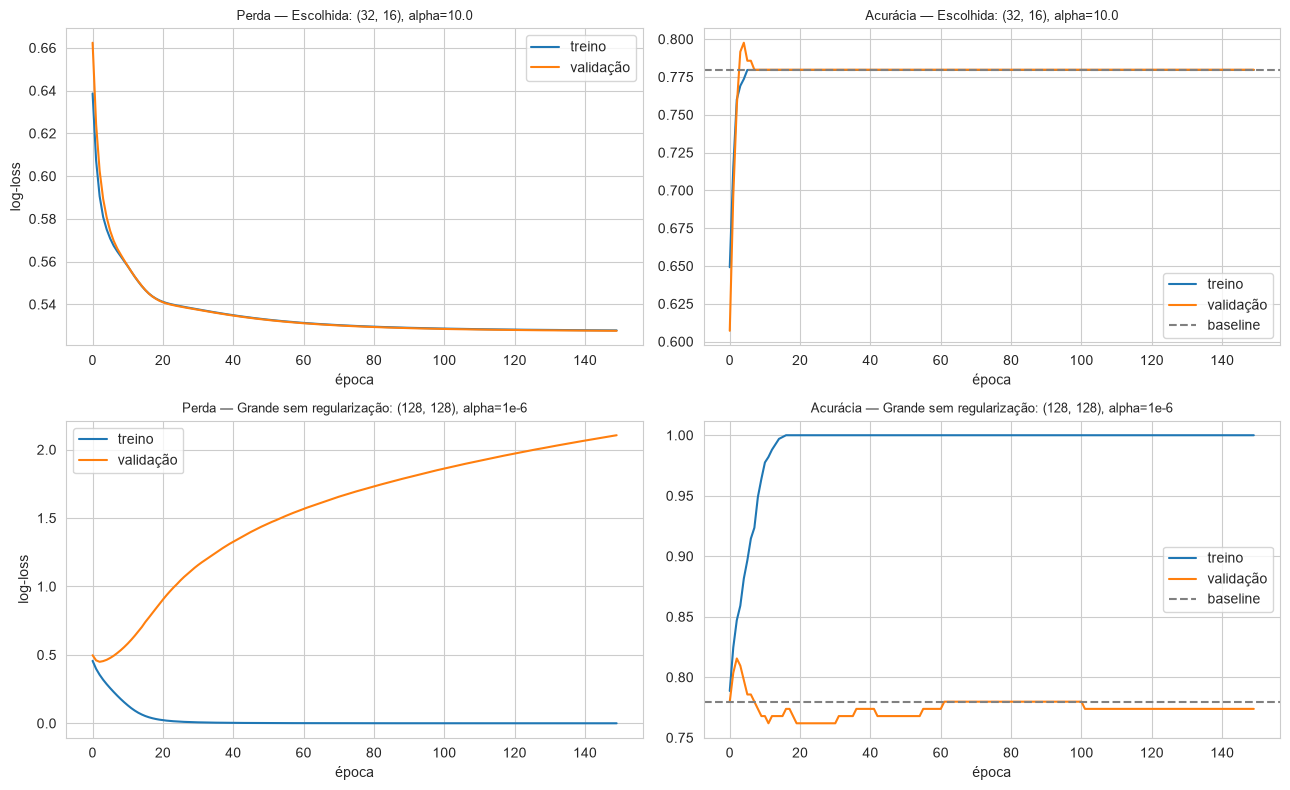

=== Diagnóstico automático ===
Escolhida: (32, 16), alpha=10.0
  menor perda de validação na época 150 (0.528); na última época: 0.528
  acurácia treino x validação (última época): 0.780 x 0.780 (diferença = -0.000)
Grande sem regularização: (128, 128), alpha=1e-6
  menor perda de validação na época 3 (0.449); na última época: 2.105
  acurácia treino x validação (última época): 1.000 x 0.774 (diferença = +0.226)


In [21]:
# Validação interna agrupada por aluno, só dentro do conjunto de desenvolvimento
i_tr, i_va = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_dev, y_dev, g_dev))
esc_c = StandardScaler().fit(X_dev.iloc[i_tr])
Xtr, Xva = esc_c.transform(X_dev.iloc[i_tr]), esc_c.transform(X_dev.iloc[i_va])
ytr, yva = y_dev.iloc[i_tr].values, y_dev.iloc[i_va].values

mlp_escolhida = modelos["Rede neural (MLP)"].best_estimator_.named_steps["mlp"]
configs = {
    f"Escolhida: {mlp_escolhida.hidden_layer_sizes}, alpha={mlp_escolhida.alpha}":
        dict(hidden_layer_sizes=mlp_escolhida.hidden_layer_sizes, alpha=mlp_escolhida.alpha),
    "Grande sem regularização: (128, 128), alpha=1e-6":
        dict(hidden_layer_sizes=(128, 128), alpha=1e-6),
}

EPOCAS = 150
historicos = {}
for nome, cfg in configs.items():
    rede = MLPClassifier(solver="adam", batch_size=32, learning_rate_init=1e-3, random_state=SEED, **cfg)
    h = {"loss_tr": [], "loss_va": [], "acc_tr": [], "acc_va": []}
    for ep in range(EPOCAS):
        rede.partial_fit(Xtr, ytr, classes=np.array([0, 1]))
        ptr, pva = rede.predict_proba(Xtr), rede.predict_proba(Xva)
        h["loss_tr"].append(log_loss(ytr, ptr, labels=[0, 1])); h["loss_va"].append(log_loss(yva, pva, labels=[0, 1]))
        h["acc_tr"].append(accuracy_score(ytr, ptr.argmax(1))); h["acc_va"].append(accuracy_score(yva, pva.argmax(1)))
    historicos[nome] = h

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for linha, (nome, h) in enumerate(historicos.items()):
    ax[linha, 0].plot(h["loss_tr"], label="treino"); ax[linha, 0].plot(h["loss_va"], label="validação")
    ax[linha, 0].set_title(f"Perda — {nome}", fontsize=9); ax[linha, 0].set_xlabel("época"); ax[linha, 0].set_ylabel("log-loss"); ax[linha, 0].legend()
    ax[linha, 1].plot(h["acc_tr"], label="treino"); ax[linha, 1].plot(h["acc_va"], label="validação")
    ax[linha, 1].axhline(1 - ytr.mean(), color="gray", ls="--", label="baseline")
    ax[linha, 1].set_title(f"Acurácia — {nome}", fontsize=9); ax[linha, 1].set_xlabel("época"); ax[linha, 1].legend()
plt.tight_layout(); plt.show()

print("=== Diagnóstico automático ===")
for nome, h in historicos.items():
    ep_min = int(np.argmin(h["loss_va"]))
    print(f"{nome}\n  menor perda de validação na época {ep_min + 1} ({h['loss_va'][ep_min]:.3f}); "
          f"na última época: {h['loss_va'][-1]:.3f}\n  acurácia treino x validação (última época): "
          f"{h['acc_tr'][-1]:.3f} x {h['acc_va'][-1]:.3f} (diferença = {h['acc_tr'][-1] - h['acc_va'][-1]:+.3f})")

**Como ler (Gráfico N1):** **sobreajuste** aparece quando a perda de treino continua caindo mas a de validação **sobe** depois de um ponto (e a acurácia de treino se afasta da de validação). **Subajuste** aparece quando as duas curvas ficam altas e juntas. Um ajuste saudável tem curvas próximas, com a de validação estabilizando.

**✏️ Diagnóstico do grupo:** classifique cada uma das duas redes (sobreajuste, subajuste ou ajuste razoável) citando a época em que a perda de validação passou a subir e a diferença de acurácia treino x validação. Explique por que a rede escolhida na validação cruzada é a regularizada. Lembre que a validação aqui é um único corte (não uma média), então as curvas são ilustrativas.

## 6. Avaliação final no teste, quadro comparativo e recomendação

**Regra de escolha (definida antes de ver o teste):** entre os modelos cuja ROC-AUC média na validação cruzada esteja dentro de **1 desvio-padrão do melhor**, recomenda-se o **mais interpretável** (ordem: árvore > Naive Bayes > KNN > rede neural). Racional: se a diferença é menor que o ruído, a complexidade extra não se justifica, e em educação a explicação importa.

ROC-AUC (CV): {'Árvore de decisão': '0.764±0.046', 'KNN': '0.780±0.022', 'Naive Bayes': '0.758±0.039', 'Rede neural (MLP)': '0.781±0.033'}
Melhor AUC média: Rede neural (MLP) | candidatos dentro de 1 desvio-padrão: ['Árvore de decisão', 'KNN', 'Naive Bayes', 'Rede neural (MLP)']
==> Modelo recomendado pela regra de parcimônia: Árvore de decisão

=== Conjunto de TESTE (única avaliação; confirmação, não seleção) ===


,Acurácia,Acurácia balanceada,Precisão (risco),Recall (risco),F1 (risco),ROC-AUC
Baseline (classe majoritária),0.780,0.500,0.000,0.000,0.000,0.500
Árvore de decisão,0.780,0.609,0.500,0.304,0.378,0.738
KNN,0.780,0.500,0.000,0.000,0.000,0.698
Naive Bayes,0.789,0.576,0.562,0.196,0.290,0.710
Rede neural (MLP),0.785,0.526,0.600,0.065,0.118,0.749


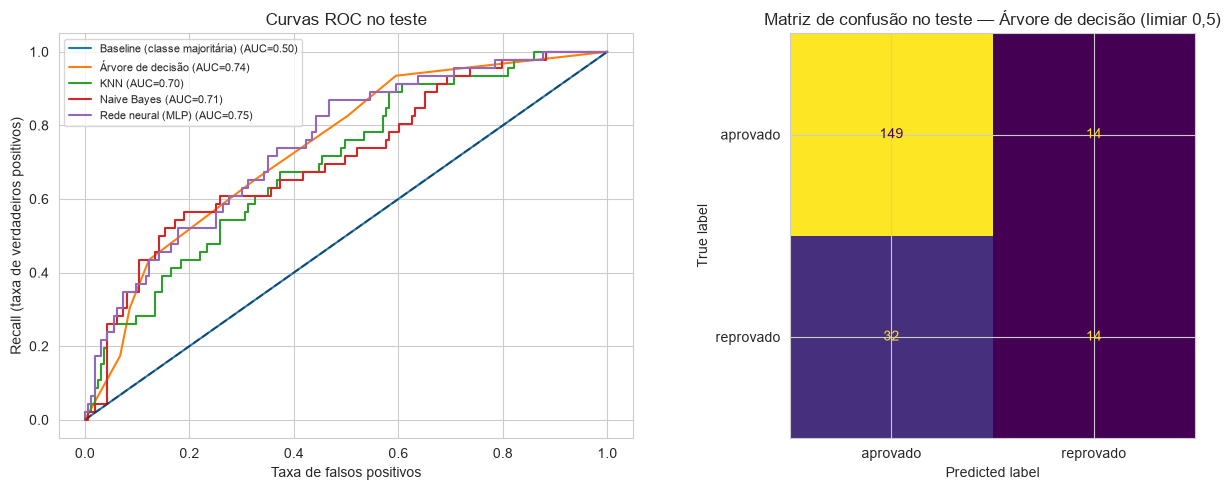

In [22]:
aucs = {n: (r["test_roc_auc"].mean(), r["test_roc_auc"].std(ddof=1)) for n, r in resultados.items() if n in modelos}
melhor = max(aucs, key=lambda n: aucs[n][0])
limite_auc = aucs[melhor][0] - aucs[melhor][1]
candidatos = [n for n in aucs if aucs[n][0] >= limite_auc]
ordem_interp = ["Árvore de decisão", "Naive Bayes", "KNN", "Rede neural (MLP)"]
recomendado = min(candidatos, key=ordem_interp.index)

print("ROC-AUC (CV):", {n: f"{m:.3f}±{s:.3f}" for n, (m, s) in aucs.items()})
print(f"Melhor AUC média: {melhor} | candidatos dentro de 1 desvio-padrão: {candidatos}")
print(f"==> Modelo recomendado pela regra de parcimônia: {recomendado}")

# Teste: uma única avaliação de cada modelo ajustado no desenvolvimento inteiro
finais = {"Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev)}
finais.update({n: m.best_estimator_ for n, m in modelos.items()})
linhas_teste, probas_teste = {}, {}
for nome, m in finais.items():
    probas_teste[nome] = m.predict_proba(X_test)[:, 1]
    linhas_teste[nome] = metricas_teste(y_test, probas_teste[nome])
tab_teste = pd.DataFrame(linhas_teste).T.round(3)

print("\n=== Conjunto de TESTE (única avaliação; confirmação, não seleção) ===")
display(tab_teste)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nome, p in probas_teste.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, p):.2f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4); ax[0].set_xlabel("Taxa de falsos positivos"); ax[0].set_ylabel("Recall (taxa de verdadeiros positivos)")
ax[0].set_title("Curvas ROC no teste"); ax[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(y_test, (probas_teste[recomendado] >= 0.5).astype(int),
                                        display_labels=["aprovado", "reprovado"], ax=ax[1], colorbar=False)
ax[1].set_title(f"Matriz de confusão no teste — {recomendado} (limiar 0,5)")
plt.tight_layout(); plt.show()

In [23]:
# Quadro comparativo final: validação cruzada (média ± desvio) e teste lado a lado
quadro = tab_cv.copy()
for col in ["ROC-AUC", "Recall (risco)", "F1 (risco)"]:
    quadro[f"{col} — teste"] = tab_teste[col].reindex(quadro.index).map("{:.3f}".format)
quadro["Interpretabilidade"] = pd.Series({"Baseline (classe majoritária)": "—", "Árvore de decisão": "alta (regras)",
                                           "Naive Bayes": "média (probabilidades por atributo)",
                                           "KNN": "baixa (sem modelo explícito)",
                                           "Rede neural (MLP)": "muito baixa (caixa-preta)"})
print("=== QUADRO COMPARATIVO FINAL ===")
display(quadro)

=== QUADRO COMPARATIVO FINAL ===


,Acurácia,Acurácia balanceada,Precisão (risco),Recall (risco),F1 (risco),ROC-AUC,ROC-AUC — teste,Recall (risco) — teste,F1 (risco) — teste,Interpretabilidade
Modelo,,,,,,,,,,
Baseline (classe majoritária),0.780 ± 0.003,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.500,0.000,0.000,—
Árvore de decisão,0.802 ± 0.018,0.599 ± 0.026,0.665 ± 0.110,0.234 ± 0.057,0.340 ± 0.065,0.764 ± 0.046,0.738,0.304,0.378,alta (regras)
KNN,0.786 ± 0.008,0.515 ± 0.018,0.500 ± 0.500,0.032 ± 0.035,0.061 ± 0.066,0.780 ± 0.022,0.698,0.000,0.000,baixa (sem modelo explícito)
Naive Bayes,0.787 ± 0.011,0.559 ± 0.023,0.566 ± 0.099,0.152 ± 0.056,0.235 ± 0.072,0.758 ± 0.039,0.710,0.196,0.290,média (probabilidades por atributo)
Rede neural (MLP),0.795 ± 0.027,0.594 ± 0.036,0.670 ± 0.186,0.233 ± 0.096,0.325 ± 0.099,0.781 ± 0.033,0.749,0.065,0.118,muito baixa (caixa-preta)


### Recomendação fundamentada

**✏️ Complete após olhar o quadro acima.** Estrutura sugerida (3 a 5 frases):

1. **Modelo recomendado** (o impresso pela regra de parcimônia, ou outro, desde que justificado) e seus números em validação cruzada (média ± desvio) e no teste.
2. **Por que ele:** diferença para os demais *dentro ou fora* do desvio entre folds; interpretabilidade; custo de errar (ver Seção 8: perder um aluno em risco custa mais que oferecer apoio a quem não precisava, então o recall da classe "reprovado" pesa mais).
3. **Quanto ele melhora sobre o baseline** nas métricas da classe de risco, e a ressalva de que a acurácia quase não muda.
4. **Condição de uso:** como **triagem para apoio pedagógico**, com revisão humana, e não como decisão automática. O limiar de decisão pode ser ajustado para priorizar recall (Seção 7).
5. **O que não sabemos:** o teste tem poucos alunos de risco, então os números têm incerteza grande (veja os intervalos de confiança na Seção 7).

## 7. Bônus — desbalanceamento (antes/depois), importância de atributos e vieses

### 7.1 Tratamento explícito do desbalanceamento
Só cerca de um quinto dos alunos está em risco (proporção exata na Seção 1). Com o limiar padrão de 0,5, os modelos tendem a "errar para o lado da maioria" (recall baixo). Duas intervenções, sempre comparadas **antes e depois**:

**(a) Pesos de classe na árvore** (`class_weight="balanced"`), na mesma validação cruzada aninhada.

In [24]:
grade_arvore = {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 40]}
arv_cw = GridSearchCV(DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
                      grade_arvore, cv=cv_interno, scoring="roc_auc")
res_cw = avaliar(arv_cw)
print("=== Árvore de decisão: ANTES (sem pesos) x DEPOIS (class_weight='balanced') — CV 5-fold ===")
display(tabela_cv({"Antes: sem pesos": resultados["Árvore de decisão"], "Depois: class_weight=balanced": res_cw}))

=== Árvore de decisão: ANTES (sem pesos) x DEPOIS (class_weight='balanced') — CV 5-fold ===


,Acurácia,Acurácia balanceada,Precisão (risco),Recall (risco),F1 (risco),ROC-AUC
Modelo,,,,,,
Antes: sem pesos,0.802 ± 0.018,0.599 ± 0.026,0.665 ± 0.110,0.234 ± 0.057,0.340 ± 0.065,0.764 ± 0.046
Depois: class_weight=balanced,0.701 ± 0.034,0.701 ± 0.041,0.400 ± 0.044,0.701 ± 0.084,0.508 ± 0.048,0.761 ± 0.038


**(b) Ajuste do limiar de decisão** do modelo recomendado. O limiar é escolhido **só com o desenvolvimento** (previsões fora da amostra por validação cruzada) maximizando F2, uma medida que pesa o recall duas vezes mais que a precisão, coerente com o custo maior de deixar passar um aluno em risco. Só depois é avaliado no teste.

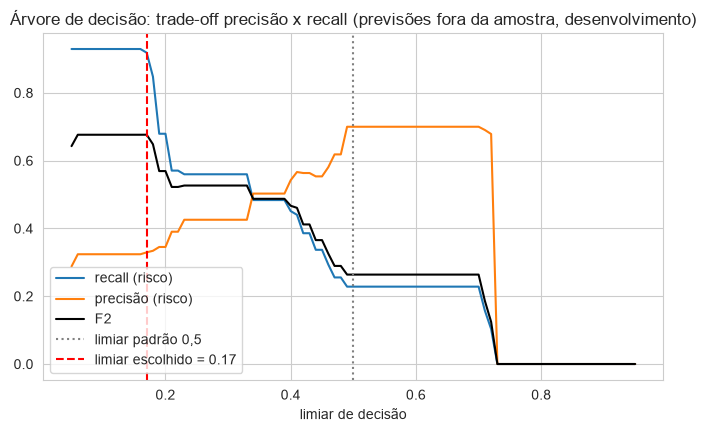

=== Árvore de decisão no TESTE: antes x depois do ajuste de limiar ===


,Acurácia,Acurácia balanceada,Precisão (risco),Recall (risco),F1 (risco),ROC-AUC
"Antes (limiar 0,5)",0.780,0.609,0.500,0.304,0.378,0.738
Depois (limiar 0.17),0.569,0.662,0.317,0.826,0.458,0.738


antes  : alunos em risco detectados = 14/46 | alertas falsos = 14 de 163 aprovados
depois : alunos em risco detectados = 38/46 | alertas falsos = 82 de 163 aprovados


In [25]:
modelo_rec = finais[recomendado]
proba_oof = cross_val_predict(clone(modelo_rec), X_dev, y_dev, cv=folds, method="predict_proba")[:, 1]

limiares = np.linspace(0.05, 0.95, 91)
f2 = np.array([fbeta_score(y_dev, proba_oof >= t, beta=2, zero_division=0) for t in limiares])
rec_l = np.array([recall_score(y_dev, proba_oof >= t, zero_division=0) for t in limiares])
pre_l = np.array([precision_score(y_dev, proba_oof >= t, zero_division=0) for t in limiares])
t_otimo = float(limiares[int(np.argmax(f2))])

plt.figure(figsize=(8, 4.5))
plt.plot(limiares, rec_l, label="recall (risco)"); plt.plot(limiares, pre_l, label="precisão (risco)")
plt.plot(limiares, f2, label="F2", color="black")
plt.axvline(0.5, color="gray", ls=":", label="limiar padrão 0,5"); plt.axvline(t_otimo, color="red", ls="--", label=f"limiar escolhido = {t_otimo:.2f}")
plt.xlabel("limiar de decisão"); plt.title(f"{recomendado}: trade-off precisão x recall (previsões fora da amostra, desenvolvimento)")
plt.legend(); plt.show()

antes_depois = pd.DataFrame({"Antes (limiar 0,5)": metricas_teste(y_test, probas_teste[recomendado], 0.5),
                             f"Depois (limiar {t_otimo:.2f})": metricas_teste(y_test, probas_teste[recomendado], t_otimo)}).T.round(3)
print(f"=== {recomendado} no TESTE: antes x depois do ajuste de limiar ===")
display(antes_depois)
for rot, lim in [("antes", 0.5), ("depois", t_otimo)]:
    tn, fp, fn, tp = confusion_matrix(y_test, (probas_teste[recomendado] >= lim).astype(int), labels=[0, 1]).ravel()
    print(f"{rot:7s}: alunos em risco detectados = {tp}/{tp + fn} | alertas falsos = {fp} de {fp + tn} aprovados")

**✏️ Leitura antes/depois:** (a) com pesos de classe, o recall da árvore sobe? A que custo de precisão? (b) no ajuste de limiar, quantos alunos em risco a mais foram detectados e quantos alertas falsos a mais foram gerados? Quem arca com o custo dos alertas falsos? (apoio extra desnecessário é barato; rótulo de "aluno problemático" não é). Note que o AUC **não muda** com o limiar: o limiar só escolhe um ponto da mesma curva ROC.

### 7.2 Importância de atributos (interpretabilidade)
Importância por **permutação** no conjunto de teste, para o modelo recomendado: quanto a ROC-AUC cai quando os valores de um atributo são embaralhados. Mais confiável que a importância interna da árvore, mas cuidado: atributos correlacionados dividem a importância entre si.

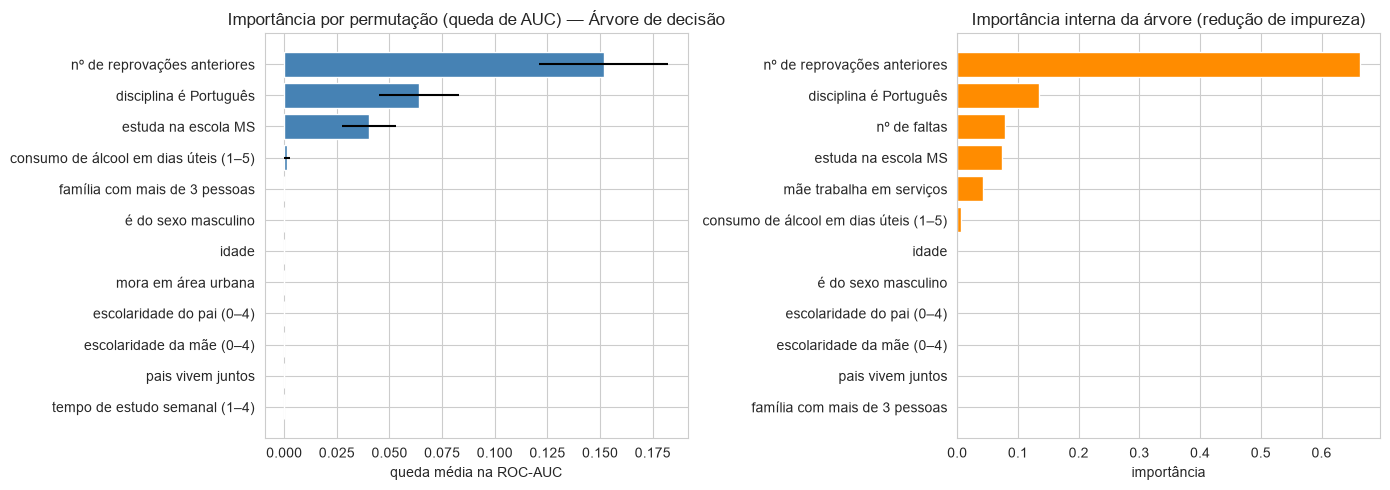

Top 5 por permutação: ['nº de reprovações anteriores', 'disciplina é Português', 'estuda na escola MS', 'consumo de álcool em dias úteis (1–5)', 'família com mais de 3 pessoas']


In [26]:
pi = permutation_importance(modelo_rec, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"media": pi.importances_mean, "dp": pi.importances_std}, index=X_test.columns).sort_values("media", ascending=False).head(12)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh([ROTULOS.get(f, f) for f in imp.index][::-1], imp["media"][::-1], xerr=imp["dp"][::-1], color="steelblue")
ax[0].set_title(f"Importância por permutação (queda de AUC) — {recomendado}"); ax[0].set_xlabel("queda média na ROC-AUC")
imp_arv = pd.Series(finais["Árvore de decisão"].feature_importances_, index=X_dev.columns).sort_values(ascending=False).head(12)
ax[1].barh([ROTULOS.get(f, f) for f in imp_arv.index][::-1], imp_arv[::-1], color="darkorange")
ax[1].set_title("Importância interna da árvore (redução de impureza)"); ax[1].set_xlabel("importância")
plt.tight_layout(); plt.show()
print("Top 5 por permutação:", [ROTULOS.get(f, f) for f in imp.index[:5]])

**✏️ Leitura:** quais atributos mais pesam? Eles aparecem também nas regras da árvore (Seção 3) e no mapa de calor dos grupos (Seção 2)? Cuidado ao concluir: **importância não é causalidade** (querer cursar ensino superior prevê melhor desempenho, mas isso não significa que mudar a resposta mude a nota). Atributos com importância perto de zero ou barras de erro que cruzam zero devem ser lidos como "sem efeito detectável".

### 7.3 Incerteza no teste e vieses por subgrupo
Com pouco mais de 200 alunos no teste e apenas algumas dezenas em risco, qualquer número é incerto. Bootstrap (1.000 reamostragens) para intervalos de 95%, e desempenho por subgrupo para procurar vieses de erro.

In [27]:
rng = np.random.default_rng(SEED)
p_fin = probas_teste[recomendado]
yt = y_test.values
res_b = {"Recall (risco)": [], "Precisão (risco)": [], "F1 (risco)": [], "ROC-AUC": []}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max():
        continue
    pr = (p_fin[i] >= t_otimo).astype(int)
    res_b["Recall (risco)"].append(recall_score(yt[i], pr, zero_division=0))
    res_b["Precisão (risco)"].append(precision_score(yt[i], pr, zero_division=0))
    res_b["F1 (risco)"].append(f1_score(yt[i], pr, zero_division=0))
    res_b["ROC-AUC"].append(roc_auc_score(yt[i], p_fin[i]))
ic = pd.DataFrame({k: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for k, v in res_b.items()},
                  index=["média", "IC95% inferior", "IC95% superior"]).T.round(3)
print(f"=== {recomendado} (limiar {t_otimo:.2f}): intervalos de confiança no teste (bootstrap) ===")
display(ic)

pred_f = (p_fin >= t_otimo).astype(int)
linhas = []
for col in ["sex", "school", "address", "disciplina"]:
    for val in sorted(meta_test[col].unique()):
        m = (meta_test[col] == val).values
        if m.sum() == 0:
            continue
        tn, fp, fn, tp = confusion_matrix(yt[m], pred_f[m], labels=[0, 1]).ravel()
        linhas.append({"atributo": col, "grupo": val, "n": int(m.sum()), "taxa real de risco": round(yt[m].mean(), 3),
                       "% sinalizados": round(pred_f[m].mean(), 3),
                       "recall": round(tp / (tp + fn), 3) if (tp + fn) else np.nan,
                       "falsos alertas (FPR)": round(fp / (fp + tn), 3) if (fp + tn) else np.nan,
                       "aviso": "n pequeno" if m.sum() < 30 or (tp + fn) < 10 else ""})
print("\n=== Desempenho por subgrupo (teste) ===")
display(pd.DataFrame(linhas).set_index(["atributo", "grupo"]))

=== Árvore de decisão (limiar 0.17): intervalos de confiança no teste (bootstrap) ===


,média,IC95% inferior,IC95% superior
Recall (risco),0.824,0.704,0.923
Precisão (risco),0.317,0.231,0.400
F1 (risco),0.456,0.356,0.547
ROC-AUC,0.735,0.654,0.813



=== Desempenho por subgrupo (teste) ===


n  taxa real de risco  % sinalizados  recall  falsos alertas (FPR) aviso
atributo   grupo                                                                                 
sex        F           134               0.254          0.619   0.853                 0.540      
           M            75               0.160          0.493   0.750                 0.444      
school     GP          151               0.192          0.417   0.724                 0.344      
           MS           58               0.293          0.983   1.000                 0.976      
address    R            68               0.221          0.750   0.933                 0.698      
           U           141               0.220          0.489   0.774                 0.409      
disciplina Matematica   81               0.309          0.753   0.800                 0.732      
           Portugues   128               0.164          0.461   0.857                 0.383

**✏️ Leitura:** (1) os intervalos de confiança são largos? Isso mostra que a diferença entre dois modelos, ou entre o modelo e um limiar, pode ser ruído. (2) Nos subgrupos, o modelo **sinaliza** e **acerta** de forma parecida? Diferenças grandes em recall ou em falsos alertas entre sexo, escola ou zona urbana/rural indicam que o erro **não é distribuído igualmente** (ver Seção 8). Subgrupos com aviso "n pequeno" não permitem conclusão.

## 8. Limitações e riscos

### O que o modelo **não** é capaz de fazer
- **Prever o destino de um aluno específico.** Com ~1.000 linhas, atributos de questionário e desempenho moderado (veja IC95% na Seção 7), o modelo serve para **triagem**, não para veredito individual.
- **Estabelecer causas.** Importâncias, regras e coeficientes são associações. Mudar um atributo (ex.: tempo de estudo) não garante mudar a nota.
- **Generalizar para outros contextos.** Os dados vêm de **duas escolas de Portugal**, coletadas em meados dos anos 2000 (Cortez & Silva, 2008). Outro país, época ou rede de ensino pode ter padrões diferentes (mudança de distribuição).
- **Usar o melhor preditor disponível.** Excluímos G1 e G2 de propósito (vazamento). Na vida real a escola tem essas notas, e um modelo com elas seria muito mais preciso, mas diria pouco sobre os fatores socioeducacionais.
- **Distinguir fenômenos diferentes.** Nota 0 (provável abandono/ausência de avaliação) e nota 8 (quase aprovado) caem na mesma classe "reprovado". A nota de corte em 10 trata como opostos alunos com 9 e 10.

### Vieses que a base carrega
- **Amostra restrita e desigual:** duas escolas e duas disciplinas com tamanhos diferentes (649 x 395); o desempenho médio por disciplina difere muito.
- **Autorrelato:** álcool, saídas e relacionamento vêm de questionário, sujeitos a viés de resposta e de desejabilidade social.
- **Atributos sensíveis e proxies:** sexo, idade, zona urbana/rural, escolaridade e profissão dos pais e relacionamento. Mesmo sem usar "classe social" diretamente, o modelo pode **discriminar indiretamente** por origem familiar.
- **O rótulo reflete critérios de avaliação dos professores** (podem variar entre escolas, disciplinas e docentes), e não uma medida objetiva de aprendizagem.
- **Alunos repetidos** entre disciplinas e dependência entre linhas: tratado na separação agrupada, mas o identificador é aproximado (atributos coincidentes podem juntar alunos distintos).

### Efeito do erro sobre as pessoas
| Erro | O que acontece com o aluno | Gravidade |
|---|---|---|
| **Falso negativo** (aluno em risco não sinalizado) | perde a chance de apoio a tempo; o problema só aparece na reprovação | **alta**, e é por isso que priorizamos o recall |
| **Falso positivo** (aluno sinalizado sem necessidade) | apoio desnecessário (baixo custo) **ou** estigma e expectativa rebaixada, com risco de profecia autorrealizável (alto custo) | depende do que a escola **faz** com o alerta |

O erro **não é igual para todos**: se a tabela por subgrupo (Seção 7.3) mostrar recall menor ou mais falsos alertas para algum grupo, esse grupo fica sistematicamente menos protegido ou mais rotulado.

**Condições mínimas para uso responsável:** apoio à decisão **humana** (nunca decisão automática); alerta que gera **apoio**, nunca punição ou segregação; transparência para alunos e famílias; monitoramento periódico de desempenho e de erros por subgrupo; reavaliação do modelo se a escola, o currículo ou o perfil dos alunos mudar.

**✏️ Acrescente** uma limitação que o grupo observou nos próprios resultados (ex.: modelo que não supera o baseline em acurácia, k-means com silhueta baixa, diferença de erro entre subgrupos).

## 9. Checklist do Marco 2

- [x] k-means com k justificado por duas evidências (cotovelo e silhueta), estabilidade e interpretação (Seção 2)
- [x] Árvore: efeito da profundidade no erro de treino e validação; regras em linguagem do domínio (Seção 3)
- [x] Regressão linear com análise de resíduos (Seção 4)
- [x] Quatro modelos de famílias distintas sob o mesmo protocolo, comparados ao baseline (Seção 5)
- [x] Validação cruzada k-fold estratificada com média e dispersão, aninhada para os hiperparâmetros (Seção 5)
- [x] Curvas de perda e acurácia da rede neural com diagnóstico (Seção 5.2)
- [x] Quadro comparativo final e recomendação (Seção 6)
- [x] Bônus: desbalanceamento antes/depois, importância de atributos, IC e subgrupos (Seção 7)
- [x] Limitações e riscos (Seção 8)
- [ ] ✏️ Concluir todas as células marcadas com ✏️ com as palavras do grupo